# Sarcina 3 – Predicția categoriei produsului pe baza titlului

Notebook complet pentru analiză, curățare, feature engineering, compararea modelelor, evaluare și salvarea modelului final.

In [1]:
import pandas as pd
import numpy as np
import re, pickle
import matplotlib.pyplot as plt
from scipy.sparse import hstack
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

DATA_PATH = "IMLP4_TASK_03-products.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
print(df.info())

Shape: (35311, 8)


,product ID,Product Title,Merchant ID,Category Label,_Product Code,Number_of_Views,Merchant Rating,Listing Date
0,1,apple iphone 8 plus 64gb silver,1,Mobile Phones,QA-2276-XC,860.0,2.5,5/10/2024
1,2,apple iphone 8 plus 64 gb spacegrau,2,Mobile Phones,KA-2501-QO,3772.0,4.8,12/31/2024
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,Mobile Phones,FP-8086-IE,3092.0,3.9,11/10/2024
3,4,apple iphone 8 plus 64gb space grey,4,Mobile Phones,YI-0086-US,466.0,3.4,5/2/2022
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,Mobile Phones,NZ-3586-WP,4426.0,1.6,4/12/2023


<class 'pandas.DataFrame'>
RangeIndex: 35311 entries, 0 to 35310
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   product ID       35311 non-null  int64  
 1   Product Title    35139 non-null  str    
 2   Merchant ID      35311 non-null  int64  
 3    Category Label  35267 non-null  str    
 4   _Product Code    35216 non-null  str    
 5   Number_of_Views  35297 non-null  float64
 6   Merchant Rating  35141 non-null  float64
 7    Listing Date    35252 non-null  str    
dtypes: float64(2), int64(2), str(4)
memory usage: 2.2 MB
None


In [2]:
df.columns = [c.strip() for c in df.columns]
print("Missing values:")
display(df.isna().sum().to_frame("missing"))

CATEGORY_MAPPING = {"fridge":"Fridge Freezers", "CPU":"CPUs", "Mobile Phone":"Mobile Phones"}
df["Category Label"] = df["Category Label"].replace(CATEGORY_MAPPING)
df = df.dropna(subset=["Product Title", "Category Label"]).copy()
df["Product Title"] = df["Product Title"].astype(str).str.strip()
df = df[df["Product Title"] != ""].copy()

print("Cleaned shape:", df.shape)
print("Categories:", df["Category Label"].nunique())
display(df["Category Label"].value_counts().to_frame("count"))

Missing values:


,missing
product ID,0
Product Title,172
Merchant ID,0
Category Label,44
_Product Code,95
Number_of_Views,14
Merchant Rating,170
Listing Date,59


Cleaned shape: (35096, 8)
Categories: 10


,count
Category Label,
Fridge Freezers,5593
Mobile Phones,4057
Washing Machines,4015
CPUs,3831
TVs,3541
Fridges,3436
Dishwashers,3405
Digital Cameras,2689
Microwaves,2328


In [3]:
# Feature engineering diagnostics from the product title
df["title_chars"] = df["Product Title"].str.len()
df["title_words"] = df["Product Title"].str.split().str.len()
df["digit_count"] = df["Product Title"].str.count(r"\d")
df["special_count"] = df["Product Title"].str.count(r"[^A-Za-z0-9\s]")
df["has_number"] = df["digit_count"] > 0
df["longest_word"] = df["Product Title"].str.split().apply(lambda x: max([len(w) for w in x], default=0))

display(df[["Product Title","title_chars","title_words","digit_count","special_count","has_number","longest_word"]].head())

,Product Title,title_chars,title_words,digit_count,special_count,has_number,longest_word
0,apple iphone 8 plus 64gb silver,31,6,3,0,True,6
1,apple iphone 8 plus 64 gb spacegrau,35,7,3,0,True,9
2,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,70,13,9,2,True,10
3,apple iphone 8 plus 64gb space grey,35,7,3,0,True,6
4,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,54,11,6,1,True,8


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df["Product Title"], df["Category Label"],
    test_size=0.20, random_state=42, stratify=df["Category Label"]
)

word = TfidfVectorizer(lowercase=True, ngram_range=(1,2), min_df=2,
                       max_df=.98, sublinear_tf=True, max_features=150000)
char = TfidfVectorizer(analyzer="char_wb", ngram_range=(3,5), min_df=2,
                       sublinear_tf=True, max_features=120000)

Xw_train = word.fit_transform(X_train)
Xw_test = word.transform(X_test)
Xc_train = char.fit_transform(X_train)
Xc_test = char.transform(X_test)

X_train_combined = hstack([Xw_train, Xc_train])
X_test_combined = hstack([Xw_test, Xc_test])

print("Word TF-IDF:", Xw_train.shape)
print("Char TF-IDF:", Xc_train.shape)
print("Combined:", X_train_combined.shape)

Word TF-IDF: (28076, 29386)
Char TF-IDF: (28076, 79501)
Combined: (28076, 108887)


In [5]:
# Model 1: Multinomial Naive Bayes
nb_model = MultinomialNB(alpha=0.1)
nb_model.fit(Xw_train, y_train)
nb_pred = nb_model.predict(Xw_test)
nb_acc = accuracy_score(y_test, nb_pred)

# Model 2: Logistic Regression
lr_model = LogisticRegression(max_iter=1000, C=5)
lr_model.fit(Xw_train, y_train)
lr_pred = lr_model.predict(Xw_test)
lr_acc = accuracy_score(y_test, lr_pred)

# Model 3: Linear SVM with word + character features
svm_model = LinearSVC(C=2.0)
svm_model.fit(X_train_combined, y_train)
svm_pred = svm_model.predict(X_test_combined)
svm_acc = accuracy_score(y_test, svm_pred)

results = pd.DataFrame({
    "Model": ["MultinomialNB", "LogisticRegression", "LinearSVC + word/char TF-IDF"],
    "Accuracy": [nb_acc, lr_acc, svm_acc]
}).sort_values("Accuracy", ascending=False)
display(results)

,Model,Accuracy
2,LinearSVC + word/char TF-IDF,0.987607
0,MultinomialNB,0.959544
1,LogisticRegression,0.957550


Classification report – final candidate (LinearSVC):
                  precision    recall  f1-score   support

            CPUs       1.00      1.00      1.00       766
 Digital Cameras       1.00      1.00      1.00       538
     Dishwashers       0.99      1.00      0.99       681
        Freezers       0.99      0.99      0.99       440
 Fridge Freezers       0.98      0.97      0.97      1119
         Fridges       0.96      0.96      0.96       687
      Microwaves       0.99      0.99      0.99       466
   Mobile Phones       0.99      1.00      1.00       812
             TVs       0.99      0.99      0.99       708
Washing Machines       0.99      0.99      0.99       803

        accuracy                           0.99      7020
       macro avg       0.99      0.99      0.99      7020
    weighted avg       0.99      0.99      0.99      7020



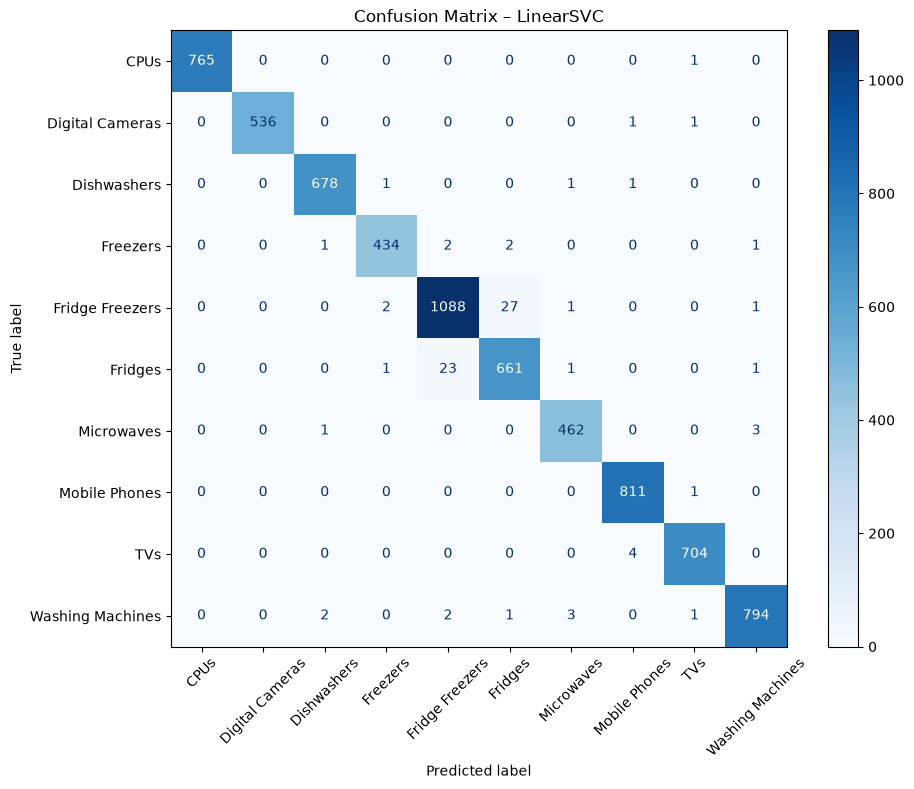

In [6]:
print("Classification report – final candidate (LinearSVC):")
print(classification_report(y_test, svm_pred))

fig, ax = plt.subplots(figsize=(10,8))
ConfusionMatrixDisplay.from_predictions(
    y_test, svm_pred, xticks_rotation=45, cmap="Blues", ax=ax
)
plt.title("Confusion Matrix – LinearSVC")
plt.tight_layout()
plt.show()

In [7]:
# Retrain final model on all cleaned data and save model.pkl
word_final = TfidfVectorizer(lowercase=True, ngram_range=(1,2), min_df=2,
                             max_df=.98, sublinear_tf=True, max_features=150000)
char_final = TfidfVectorizer(analyzer="char_wb", ngram_range=(3,5), min_df=2,
                             sublinear_tf=True, max_features=120000)

Xw_all = word_final.fit_transform(df["Product Title"])
Xc_all = char_final.fit_transform(df["Product Title"])

final_model = LinearSVC(C=2.0)
final_model.fit(hstack([Xw_all, Xc_all]), df["Category Label"])

artifact = {
    "word_vectorizer": word_final,
    "char_vectorizer": char_final,
    "model": final_model,
    "category_mapping": CATEGORY_MAPPING,
    "model_name": "LinearSVC + word/character TF-IDF"
}

with open("model.pkl", "wb") as f:
    pickle.dump(artifact, f)

print("Saved model.pkl")

Saved model.pkl


In [8]:
# Manual tests required by the assignment
def predict_category(title):
    Xw = word_final.transform([title])
    Xc = char_final.transform([title])
    return final_model.predict(hstack([Xw, Xc]))[0]

test_titles = [
    "iphone 7 32gb gold",
    "olympus e m10 mark iii geh use silber",
    "kenwood k20mss15 solo",
    "bosch wap28390gb 8kg 1400 spin",
    "bosch serie 4 kgv39vl31g",
    "smeg sbs8004po",
]
for title in test_titles:
    print(f"{title} -> {predict_category(title)}")

iphone 7 32gb gold -> Mobile Phones
olympus e m10 mark iii geh use silber -> Digital Cameras
kenwood k20mss15 solo -> Microwaves
bosch wap28390gb 8kg 1400 spin -> Washing Machines
bosch serie 4 kgv39vl31g -> Fridge Freezers
smeg sbs8004po -> Fridge Freezers
